# Titanic: análise exploratória e classificação

Projeto de estudo realizado em 11 e 12/10/2026, como prática complementar ao Módulo 03 do ML Zoomcamp. O objetivo foi aprender a investigar os dados, preparar features, comparar configurações na validação e avaliar um modelo de regressão logística no teste reservado.

Fonte: [Titanic — Kaggle](https://www.kaggle.com/competitions/titanic/data). Usamos apenas o `train.csv`, com 891 passageiros e o alvo `Survived` (0: não sobreviveu; 1: sobreviveu). O `test.csv` da competição não é nosso teste local: suas respostas não estão disponíveis.

O desenvolvimento foi guiado, com apoio de IA para explicações e revisão. As células foram executadas localmente pelo estudante. Este notebook mantém os experimentos e as saídas desse percurso.

## 1. Inspeção inicial

CSV e notebook devem estar no mesmo diretório de trabalho. Conferimos tamanho, tipos e ausentes antes de preparar os dados.

In [5]:
import pandas as pd

df = pd.read_csv("train.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
df.shape

(891, 12)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [9]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [10]:
df["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [11]:
df["Survived"].value_counts(normalize=True) * 100

Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

## 2. Treino, validação e teste

A divisão é estratificada pelo alvo e usa `random_state=42`. Reservamos primeiro aproximadamente 20% para teste; depois separamos 25% dos 80% restantes para validação. Resultado: **534 no treino, 178 na validação e 179 no teste**.

As inspeções iniciais da base completa descrevem o arquivo. As análises que orientam as features e os parâmetros de preparação usam o treino. O teste fica reservado até a escolha final.

In [12]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["Survived"]
)

df_full_train.shape, df_test.shape

((712, 12), (179, 12))

In [13]:
df_train, df_val = train_test_split(
    df_full_train,
    test_size=0.25,
    random_state=42,
    stratify=df_full_train["Survived"]
)

df_train.shape, df_val.shape

((534, 12), (178, 12))

## 3. Análise exploratória do treino

A média de uma coluna com valores 0 e 1 é a proporção de sobreviventes. Os percentuais de cada grupo usam seus próprios passageiros como denominador. Associações observadas não demonstram causas.

In [14]:
df_train.groupby("Sex")["Survived"].mean()

Sex
female    0.740741
male      0.188406
Name: Survived, dtype: float64

In [15]:
df_train.groupby("Pclass")["Survived"].mean()

Pclass
1    0.664062
2    0.403509
3    0.253425
Name: Survived, dtype: float64

In [16]:
df_train[["Age", "Fare"]].describe()

,Age,Fare
count,436.000000,534.000000
mean,30.125206,31.246645
std,14.518754,46.129696
min,0.420000,0.000000
25%,21.000000,7.925000
50%,29.000000,14.454200
75%,39.000000,30.053100
max,80.000000,512.329200


In [17]:
df_train["Pclass"].value_counts(normalize=True).sort_index() * 100

Pclass
1    23.970037
2    21.348315
3    54.681648
Name: proportion, dtype: float64

### Tarifas: distribuição e classe

A média de Fare é 31,25 e a mediana é 14,45. O histograma mostra concentração em tarifas menores e uma cauda à direita. Tarifas altas não são automaticamente erros. A mediana por classe ajuda a comparar o centro dos valores sem tanta influência dos extremos.

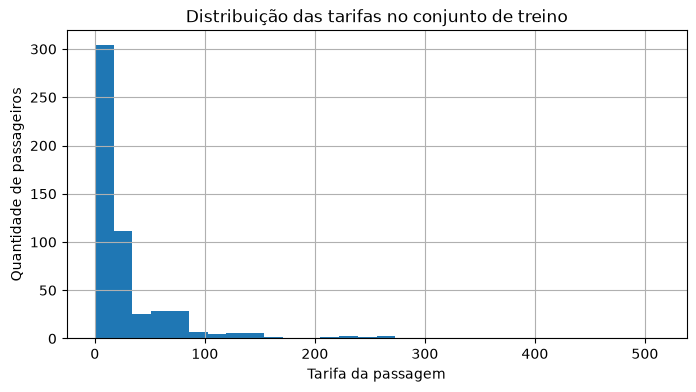

In [18]:
import matplotlib.pyplot as plt

df_train["Fare"].hist(bins=30, figsize=(8, 4))

plt.xlabel("Tarifa da passagem")
plt.ylabel("Quantidade de passageiros")
plt.title("Distribuição das tarifas no conjunto de treino")
plt.show()

In [19]:
df_train.groupby("Pclass")["Fare"].median()

Pclass
1    57.45420
2    13.67915
3     8.05000
Name: Fare, dtype: float64

### Idades: centro e faixas

Idade média e mediana não identificam o intervalo mais frequente do histograma. As medianas de sobreviventes e não sobreviventes são iguais a 29, mas isso não torna Age inútil: as taxas por faixa podem ser diferentes. Estes cálculos ignoram idades ausentes.

Os rótulos das faixas são abreviações: após a primeira faixa, os intervalos são (12, 18], (18, 40], (40, 60] e (60, infinito]. Assim, uma idade fracionária como 12,5 pertence ao segundo intervalo.

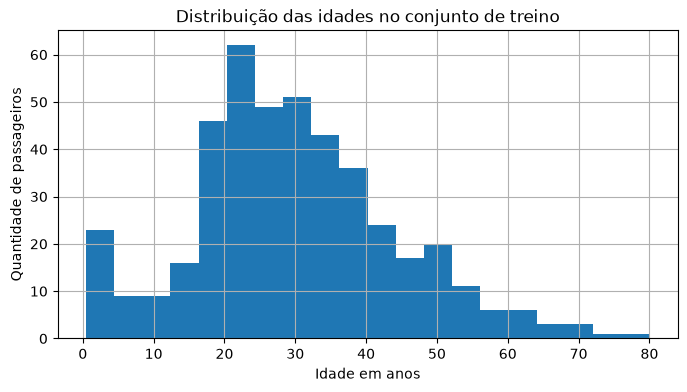

In [20]:
df_train["Age"].hist(bins=20, figsize=(8, 4))

plt.xlabel("Idade em anos")
plt.ylabel("Quantidade de passageiros")
plt.title("Distribuição das idades no conjunto de treino")
plt.show()

In [21]:
df_train.groupby("Survived")["Age"].median()

Survived
0    29.0
1    29.0
Name: Age, dtype: float64

In [22]:
faixa_idade = pd.cut(
    df_train["Age"],
    bins=[0, 12, 18, 40, 60, float("inf")],
    labels=["0–12", "13–18", "19–40", "41–60", "Acima de 60"],
    right=True,
    include_lowest=True
)

df_train.groupby(faixa_idade, observed=True)["Survived"].agg(
    ["count", "mean"]
)

,count,mean
Age,,
0–12,41,0.634146
13–18,37,0.405405
19–40,266,0.375940
41–60,78,0.423077
Acima de 60,14,0.214286


### Porto, classe e sobrevivência

Investigamos a hipótese de que a composição das classes ajuda a entender diferenças entre portos. `normalize="index"` calcula percentuais dentro de cada porto; sem normalização, a tabela mostra quantidades. C tem maior proporção de primeira classe, mas S tem maior quantidade absoluta nessa classe.

Na primeira classe, as taxas de C e S são próximas; na terceira, permanece uma diferença. A classe não explica sozinha todas as diferenças observadas. Grupos com um passageiro, como Q nas primeiras duas classes, não sustentam conclusões fortes.

In [23]:
df_train.groupby("Embarked")["Survived"].agg(["count", "mean"])

,count,mean
Embarked,,
C,109,0.532110
Q,41,0.463415
S,382,0.329843


In [24]:
pd.crosstab(
    df_train["Embarked"],
    df_train["Pclass"],
    normalize="index"
) * 100

Pclass,1,2,3
Embarked,,,
C,49.541284,10.091743,40.366972
Q,2.439024,2.439024,95.121951
S,18.586387,26.701571,54.712042


In [25]:
pd.crosstab(
    df_train["Embarked"],
    df_train["Pclass"]
)

Pclass,1,2,3
Embarked,,,
C,54,11,44
Q,1,1,39
S,71,102,209


In [26]:
df_train.groupby(
    ["Embarked", "Pclass"]
)["Survived"].agg(["count", "mean"])

count      mean
Embarked Pclass                 
C        1          54  0.666667
         2          11  0.454545
         3          44  0.386364
Q        1           1  1.000000
         2           1  1.000000
         3          39  0.435897
S        1          71  0.647887
         2         102  0.392157
         3         209  0.191388

## 4. Features familiares derivadas

`FamilySize = SibSp + Parch + 1` inclui o próprio passageiro. `IsAlone` indica ausência de familiares registrados nessas duas colunas, não ausência de amigos ou acompanhantes.

O tamanho familiar 4 teve a maior taxa observada (75%, 15 de 20). Os grupos maiores têm poucos registros. FamilySize será avaliada como alternativa no modelo; IsAlone fica apenas na exploração deste exercício.

In [27]:
df_train = df_train.copy()

df_train["FamilySize"] = (
    df_train["SibSp"] + df_train["Parch"] + 1
)

df_train.groupby("FamilySize")["Survived"].agg(["count", "mean"])

,count,mean
FamilySize,,
1,323,0.297214
2,96,0.510417
3,59,0.644068
4,20,0.750000
5,8,0.375000
6,13,0.076923
7,7,0.428571
8,4,0.000000
11,4,0.000000


In [28]:
df_train["IsAlone"] = (
    df_train["FamilySize"] == 1
).astype(int)

df_train.groupby("IsAlone")["Survived"].agg(["count", "mean"])

,count,mean
IsAlone,,
0,211,0.516588
1,323,0.297214


## 5. Tratamento de ausentes

Aprendemos **mediana de Age = 29** e **moda de Embarked = S** somente no treino e aplicamos os mesmos valores à validação e, ao final, ao teste. `fillna` preserva os valores presentes. Imputar não revela a idade ou o porto verdadeiro.

Há 98 idades ausentes no treino; os 177 ausentes eram da base completa. Cabin não será usada no primeiro modelo.

In [29]:
mediana_age = df_train["Age"].median()

mediana_age

np.float64(29.0)

In [30]:
df_train["Age"] = df_train["Age"].fillna(mediana_age)

df_train["Age"].isna().sum()

np.int64(0)

In [31]:
df_val = df_val.copy()

df_val["Age"] = df_val["Age"].fillna(mediana_age)

df_val["Age"].isna().sum()

np.int64(0)

In [32]:
df_train["Embarked"].mode()

0    S
Name: Embarked, dtype: str

In [33]:
moda_embarked = df_train["Embarked"].mode().iloc[0]

df_train["Embarked"] = df_train["Embarked"].fillna(moda_embarked)
df_val["Embarked"] = df_val["Embarked"].fillna(moda_embarked)

df_train["Embarked"].isna().sum(), df_val["Embarked"].isna().sum()

(np.int64(0), np.int64(0))

In [34]:
df_val["FamilySize"] = (
    df_val["SibSp"] + df_val["Parch"] + 1
)

df_val["IsAlone"] = (
    df_val["FamilySize"] == 1
).astype(int)

df_val[["SibSp", "Parch", "FamilySize", "IsAlone"]].head()

,SibSp,Parch,FamilySize,IsAlone
320,0,0,1,1
131,0,0,1,1
316,1,0,2,0
89,0,0,1,1
154,0,0,1,1


## 6. Features e codificação

O primeiro modelo usa Pclass, Sex, Age, SibSp, Parch, Fare e Embarked. PassengerId, Name, Ticket e Cabin ficam fora desta configuração inicial, sem afirmar que seriam sempre inúteis.

O alvo fica separado em y. DictVectorizer mantém as cinco features numéricas, incluindo Pclass, e cria duas colunas para Sex e três para Embarked: dez colunas no total. **Pclass não foi codificada como categoria**. O codificador é ajustado no treino e apenas aplicado aos demais conjuntos.

In [35]:
features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked"
]

X_train = df_train[features].copy()
y_train = df_train["Survived"].copy()

X_val = df_val[features].copy()
y_val = df_val["Survived"].copy()

X_train.shape, y_train.shape, X_val.shape, y_val.shape

((534, 7), (534,), (178, 7), (178,))

In [36]:
train_dicts = X_train.to_dict(orient="records")

train_dicts[0]

{'Pclass': 1,
 'Sex': 'female',
 'Age': 39.0,
 'SibSp': 1,
 'Parch': 0,
 'Fare': 55.9,
 'Embarked': 'S'}

In [37]:
for coluna in ["Sex", "Embarked"]:
    print(coluna, X_train[coluna].unique())

Sex <StringArray>
['female', 'male']
Length: 2, dtype: str
Embarked <StringArray>
['S', 'C', 'Q']
Length: 3, dtype: str


In [38]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)

X_train_encoded = dv.fit_transform(train_dicts)

dv.get_feature_names_out()

array(['Age', 'Embarked=C', 'Embarked=Q', 'Embarked=S', 'Fare', 'Parch',
       'Pclass', 'Sex=female', 'Sex=male', 'SibSp'], dtype=object)

In [39]:
X_train_encoded.shape, X_train_encoded[0]

((534, 10),
 array([39. ,  0. ,  0. ,  1. , 55.9,  0. ,  1. ,  1. ,  0. ,  1. ]))

In [40]:
val_dicts = X_val.to_dict(orient="records")

X_val_encoded = dv.transform(val_dicts)

X_val_encoded.shape

(178, 10)

## 7. Padronização e treinamento

StandardScaler usa `(valor − média do treino) / desvio padrão do treino`. Aqui todas as dez colunas são padronizadas, inclusive os indicadores. Isso não é transformação logarítmica e não elimina a assimetria de Fare.

A regressão logística aprende pesos e intercepto e usa a sigmoide para estimar probabilidades. Mantemos a regularização L2 padrão e `C=1`. `max_iter=1000` é o limite de iterações. No solver padrão lbfgs, random_state não influencia a otimização. O painel do modelo mostra parâmetros aprendidos, não desempenho.

In [41]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_encoded)
X_val_scaled = scaler.transform(X_val_encoded)

X_train_scaled.shape, X_val_scaled.shape

((534, 10), (178, 10))

In [42]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, random_state=42)

model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

## 8. Probabilidades e avaliação na validação

Com classes [0, 1], predict_proba retorna primeiro a probabilidade da classe 0 e depois da classe 1. Usamos a segunda coluna e limiar 0,50. O resultado real é um fato registrado, não uma probabilidade.

Acurácia = acertos / total. Baseline: sempre prever 0, a classe mais frequente no treino. Ambas as estratégias são avaliadas nos mesmos 178 passageiros.

In [43]:
probabilidades_val = model.predict_proba(X_val_scaled)

probabilidades_val[:5]

array([[0.897586  , 0.102414  ],
       [0.89001102, 0.10998898],
       [0.19229494, 0.80770506],
       [0.90449079, 0.09550921],
       [0.92075233, 0.07924767]])

In [44]:
prob_sobrevivencia_val = probabilidades_val[:, 1]

y_pred_val = (prob_sobrevivencia_val >= 0.50).astype(int)

y_pred_val[:5]

array([0, 0, 1, 0, 0])

In [45]:
comparacao = pd.DataFrame({
    "real": y_val.to_numpy(),
    "previsto": y_pred_val,
    "prob_sobrevivencia": prob_sobrevivencia_val
})

comparacao.head()

,real,previsto,prob_sobrevivencia
0,0,0,0.102414
1,0,0,0.109989
2,1,1,0.807705
3,0,0,0.095509
4,0,0,0.079248


In [46]:
comparacao["acertou"] = (
    comparacao["real"] == comparacao["previsto"]
)

acuracia_val = comparacao["acertou"].mean()

acuracia_val

np.float64(0.797752808988764)

In [47]:
acuracia_baseline = (y_val == 0).mean()

acuracia_baseline, acuracia_val

(np.float64(0.6179775280898876), np.float64(0.797752808988764))

### Matriz de confusão, recall e precisão

Linhas são resultados reais; colunas são previsões. A diagonal contém os acertos. Positivo significa a classe sobrevivente (1).

- Verdadeiro positivo: real 1, previsto 1.
- Falso negativo: real 1, previsto 0.
- Falso positivo: real 0, previsto 1.
- Verdadeiro negativo: real 0, previsto 0.

**Recall:** TP / (TP + FN), entre sobreviventes reais, quantos identificamos?

**Precisão:** TP / (TP + FP), entre previsões de sobrevivência, quantas estão corretas?

In [48]:
matriz_confusao = pd.crosstab(
    comparacao["real"],
    comparacao["previsto"],
    rownames=["Real"],
    colnames=["Previsto"]
)

matriz_confusao

Previsto,0,1
Real,,
0,95,15
1,21,47


In [49]:
verdadeiros_positivos = matriz_confusao.loc[1, 1]
falsos_negativos = matriz_confusao.loc[1, 0]

recall_val = verdadeiros_positivos / (
    verdadeiros_positivos + falsos_negativos
)

recall_val

np.float64(0.6911764705882353)

In [50]:
falsos_positivos = matriz_confusao.loc[0, 1]

precisao_val = verdadeiros_positivos / (
    verdadeiros_positivos + falsos_positivos
)

precisao_val

np.float64(0.7580645161290323)

## 9. Experimento com limiar de 30%

O modelo e as probabilidades permanecem iguais; muda somente a regra de decisão. As previsões positivas passam de 62 para 85: mais dez sobreviventes identificados e mais treze falsos positivos. O total real de sobreviventes continua 68.

Com 0,30, o recall aumenta para 83,82%, enquanto precisão cai para 67,06% e acurácia para 78,09%. A escolha depende do erro que se quer reduzir. Para comparar features neste exercício, mantemos limiar 0,50 e acurácia como critério.

In [51]:
y_pred_val_030 = (
    prob_sobrevivencia_val >= 0.30
).astype(int)

matriz_confusao_030 = pd.crosstab(
    y_val.to_numpy(),
    y_pred_val_030,
    rownames=["Real"],
    colnames=["Previsto"]
)

matriz_confusao_030

Previsto,0,1
Real,,
0,82,28
1,11,57


In [52]:
acuracia_val_030 = (
    y_val.to_numpy() == y_pred_val_030
).mean()

acuracia_val_030

0.7808988764044944

In [53]:
tp_030 = int(matriz_confusao_030.loc[1, 1])
fn_030 = int(matriz_confusao_030.loc[1, 0])

recall_val_030 = tp_030 / (tp_030 + fn_030)

recall_val_030

0.8382352941176471

In [54]:
fp_030 = int(matriz_confusao_030.loc[0, 1])

precisao_val_030 = tp_030 / (tp_030 + fp_030)

precisao_val_030

0.6705882352941176

## 10. Comparação de features: sem porto

Retiramos Embarked mantendo divisão, configuração do modelo e limiar. Codificador, padronizador e modelo são objetos separados. A relação entre porto e classe não implica que o porto seja redundante para a previsão.

Resultado na validação: 139 acertos (78,09%), contra 142 no original. Diferença de três passageiros nesta amostra.

In [55]:
features_sem_porto = [
    feature
    for feature in features
    if feature != "Embarked"
]

features_sem_porto

['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare']

In [56]:
train_dicts_sem_porto = df_train[
    features_sem_porto
].to_dict(orient="records")

val_dicts_sem_porto = df_val[
    features_sem_porto
].to_dict(orient="records")

dv_sem_porto = DictVectorizer(sparse=False)

X_train_sem_porto = dv_sem_porto.fit_transform(train_dicts_sem_porto)
X_val_sem_porto = dv_sem_porto.transform(val_dicts_sem_porto)

X_train_sem_porto.shape, X_val_sem_porto.shape

((534, 7), (178, 7))

In [57]:
scaler_sem_porto = StandardScaler()

X_train_sem_porto_scaled = scaler_sem_porto.fit_transform(
    X_train_sem_porto
)

X_val_sem_porto_scaled = scaler_sem_porto.transform(
    X_val_sem_porto
)

X_train_sem_porto_scaled.shape, X_val_sem_porto_scaled.shape

((534, 7), (178, 7))

In [58]:
model_sem_porto = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_sem_porto.fit(
    X_train_sem_porto_scaled,
    y_train
)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [59]:
prob_sem_porto = model_sem_porto.predict_proba(
    X_val_sem_porto_scaled
)[:, 1]

y_pred_sem_porto = (prob_sem_porto >= 0.50).astype(int)

acuracia_sem_porto = (
    y_val.to_numpy() == y_pred_sem_porto
).mean()

acuracia_val, acuracia_sem_porto

(np.float64(0.797752808988764), np.float64(0.7808988764044944))

## 11. Comparação de features: FamilySize

Substituímos SibSp e Parch por FamilySize. A soma preserva o tamanho familiar, mas perde a distinção entre tipos de parentes. A nova representação tem nove colunas codificadas.

Resultado: 141 acertos (79,21%), um a menos que o original. As diferenças pequenas em uma única validação não demonstram superioridade geral.

In [60]:
features_familia = [
    "Pclass",
    "Sex",
    "Age",
    "Fare",
    "Embarked",
    "FamilySize"
]

features_familia

['Pclass', 'Sex', 'Age', 'Fare', 'Embarked', 'FamilySize']

In [61]:
train_dicts_familia = df_train[
    features_familia
].to_dict(orient="records")

val_dicts_familia = df_val[
    features_familia
].to_dict(orient="records")

dv_familia = DictVectorizer(sparse=False)

X_train_familia = dv_familia.fit_transform(train_dicts_familia)
X_val_familia = dv_familia.transform(val_dicts_familia)

X_train_familia.shape, X_val_familia.shape

((534, 9), (178, 9))

In [62]:
scaler_familia = StandardScaler()

X_train_familia_scaled = scaler_familia.fit_transform(
    X_train_familia
)

X_val_familia_scaled = scaler_familia.transform(
    X_val_familia
)

X_train_familia_scaled.shape, X_val_familia_scaled.shape

((534, 9), (178, 9))

In [63]:
model_familia = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_familia.fit(
    X_train_familia_scaled,
    y_train
)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [64]:
prob_familia = model_familia.predict_proba(
    X_val_familia_scaled
)[:, 1]

y_pred_familia = (prob_familia >= 0.50).astype(int)

acuracia_familia = (
    y_val.to_numpy() == y_pred_familia
).mean()

acuracia_val, acuracia_sem_porto, acuracia_familia

(np.float64(0.797752808988764),
 np.float64(0.7808988764044944),
 np.float64(0.7921348314606742))

## 12. Escolha e avaliação final no teste

Escolhemos o modelo original e limiar 0,50 pela acurácia na validação. Mantemos o modelo ajustado aos 534 passageiros: **não houve retreinamento com treino e validação juntos**.

O teste recebe o preenchimento, a codificação e a escala já definidos no treino. Não há novo fit. Seus resultados serão relatados sem usar o teste para novas escolhas.

In [65]:
df_test = df_test.copy()

df_test["Age"] = df_test["Age"].fillna(mediana_age)
df_test["Embarked"] = df_test["Embarked"].fillna(moda_embarked)

df_test[["Age", "Embarked"]].isna().sum()

Age         0
Embarked    0
dtype: int64

In [66]:
test_dicts = df_test[features].to_dict(orient="records")

X_test_encoded = dv.transform(test_dicts)

X_test_scaled = scaler.transform(X_test_encoded)

X_test_scaled.shape

(179, 10)

In [67]:
y_test = df_test["Survived"].to_numpy()

prob_test = model.predict_proba(X_test_scaled)[:, 1]

y_pred_test = (prob_test >= 0.50).astype(int)

acertos_test = (y_test == y_pred_test).sum()
acuracia_test = (y_test == y_pred_test).mean()

acertos_test, acuracia_test

(np.int64(143), np.float64(0.7988826815642458))

In [68]:
matriz_confusao_test = pd.crosstab(
    y_test,
    y_pred_test,
    rownames=["Real"],
    colnames=["Previsto"]
)

matriz_confusao_test

Previsto,0,1
Real,,
0,95,15
1,21,48


In [69]:
tp_test = int(matriz_confusao_test.loc[1, 1])
fn_test = int(matriz_confusao_test.loc[1, 0])
fp_test = int(matriz_confusao_test.loc[0, 1])

recall_test = tp_test / (tp_test + fn_test)
precisao_test = tp_test / (tp_test + fp_test)

recall_test, precisao_test

(0.6956521739130435, 0.7619047619047619)

## Conclusões

| Configuração | Validação: acurácia | Acertos |
|---|---:|---:|
| Baseline sempre 0 | 61,80% | 110/178 |
| Original, limiar 0,50 | 79,78% | 142/178 |
| Original, limiar 0,30 | 78,09% | 139/178 |
| Sem porto, limiar 0,50 | 78,09% | 139/178 |
| FamilySize, limiar 0,50 | 79,21% | 141/178 |

**Teste final:** acurácia 79,89% (143/179), recall 69,57% (48/69), precisão 76,19% (48/63). Matriz: [[95, 15], [21, 48]], com linhas reais e colunas previstas.

O principal aprendizado foi conectar exploração, hipóteses, preparação e avaliação. O modelo superou o baseline na validação; mudar o limiar mostrou a troca entre tipos de erro. Retirar porto reduziu três acertos e resumir a família reduziu um nesta amostra.

Limitações: dataset pequeno e histórico, uma única divisão, sem validação cruzada ou inferência causal. Pclass foi tratada numericamente; não houve ajuste de C ou transformação logarítmica. Os resultados não demonstram prontidão para produção nem desempenho em outra população. Idades imputadas não são idades verdadeiras. Extensões devem ser feitas em um novo ciclo de avaliação, sem usar este teste já observado para orientar ajustes.